# Sampling evaluation results

- Dependencies: Jupyter, pandas, NumPy, SciPy, Matplotlib
- Inputs: `evaluation.final.csv`, `evaluation.quality.csv`
- Combination: historical model × local model, within application and workload
- `corrected-<model>`: fixed historical model × build-specific correction factor learned by `<model>` from measurements on the target hardware

In [18]:
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.stats import t

In [19]:
RESULTS_DIR = Path("evaluation-results-3seeds-25steps")
HARDWARE = None  # Exact platform name or None for all platforms + average
EXPECTED_LAST_STEP = 25
EXPECTED_COLD_SEEDS = 3

## Snapshot and coverage

- Random baseline excluded from coverage, rankings, ranges and plots
- Completed sessions only: matching final row, full prediction trace, configured final step
- Completed combinations only: configured cold-start seed count; one historical run
- Snapshot coverage only; possible additional platforms, combinations and seeds
- Cross-hardware comparison: shared combinations with usable data on every observed platform

In [20]:
COMBO = ["application", "workload", "pretrained", "model"]
GROUP = ["platform", *COMBO]
RUN = [*GROUP, "seed"]
TIMINGS = ["prediction_seconds", "next_sample_seconds", "refit_seconds"]


def snapshot(name, columns):
    path = RESULTS_DIR / f"evaluation.{name}.csv"
    with path.open("rb") as file:
        data = file.read(path.stat().st_size)
    # Complete physical lines only; evaluation records use single-line fields
    return pd.read_csv(BytesIO(data[:data.rfind(b"\n") + 1]), usecols=columns,
                       keep_default_na=False, na_values=[""])


final = snapshot("final", [*RUN, "final_step", "prediction_count", "stable_final_build_round"])
quality = snapshot("quality", [
    *RUN, "step", "round", "recommended_measured_performance",
    "recommended_predicted_performance", "recommended_percent_of_best_observed",
    "recommended_percent_of_pool_best", *TIMINGS,
])
for frame in (final, quality):
    frame.drop(index=frame.index[frame["model"].eq("random")], inplace=True)
    frame["workload"] = frame["workload"].fillna("")

platforms = sorted(set(final["platform"]) | set(quality["platform"]))
if HARDWARE not in [None, *platforms]:
    raise ValueError(f"Unknown platform: {HARDWARE!r}. Available platforms: {platforms}")
if HARDWARE is not None:
    platforms = [HARDWARE]
    final = final.loc[final["platform"].eq(HARDWARE)].copy()
    quality = quality.loc[quality["platform"].eq(HARDWARE)].copy()

if final.duplicated(RUN).any() or quality.duplicated([*RUN, "step"]).any():
    raise ValueError("Duplicate session or prediction keys; use one evaluation campaign per directory.")

seen = pd.concat([quality[GROUP], final[GROUP]]).drop_duplicates()
trace = quality.groupby(RUN).agg(
    rows=("round", "size"), rounds=("round", "nunique"),
    first_round=("round", "min"), last_round=("round", "max"), last_step=("step", "max"),
)
final = final.merge(trace, on=RUN, how="inner", validate="one_to_one")
complete = (
    final["final_step"].eq(EXPECTED_LAST_STEP)
    & final["last_step"].eq(final["final_step"])
    & final["rows"].eq(final["prediction_count"])
    & final["rounds"].eq(final["prediction_count"])
    & (final["last_round"] - final["first_round"] + 1).eq(final["prediction_count"])
)
final = final.loc[complete].copy()
expected = np.where(final["pretrained"].eq("none"), EXPECTED_COLD_SEEDS, 1)
final = final.loc[final.groupby(GROUP)["seed"].transform("size").eq(expected)].copy()
quality = quality.merge(final[RUN], on=RUN, how="inner", validate="many_to_one")

coverage = pd.DataFrame(index=pd.Index(platforms, name="platform"))
coverage["Combinations seen"] = seen.groupby("platform").size()
coverage["Combinations ready"] = final[GROUP].drop_duplicates().groupby("platform").size()
coverage["Completed sessions in ready combinations"] = final.groupby("platform").size()
display(coverage.fillna(0).astype(int))

,Combinations seen,Combinations ready,Completed sessions in ready combinations
platform,,,
AMD Ryzen 7 5800X 8-Core Processor,420,420,460
AMD Ryzen 7 8845HS w/ Radeon 780M Graphics,420,420,460
AMD Ryzen 9 3900X 12-Core Processor,109,109,149


## Metrics and ranking

- Accuracy (%): 100 × (1 − |predicted throughput − measured throughput| / measured throughput); negative above 100% relative error (e.g., predicted 250, measured 100 → −50%)
- Improvement (percentage points): last minus first prediction accuracy, paired within each session
- Recommendation quality (%): measured throughput of the recommended build ÷ best measured throughput in the full replay pool × 100
- Recommendation quality improvement (pp): last minus first recommendation quality within each session
- Local convergence (round): first round of the uninterrupted run of the final recommendation
- Timing (ms): mean per recorded round, then mean of session means; zero refit for no-op refits
- Missing throughput or timing: no imputation; unavailable metrics excluded from rankings
- Hardware means: equal session weights; 95% Student t intervals across seeds
- Cross-hardware means: equal hardware weights; 95% Student t intervals across hardware means
- Intervals: pointwise, exploratory; no interval with one replicate; no adjustment for selection
- Companion values: mean [95% CI], where available
- Ranges: min–max of eligible combination means, before top-five selection
- Ties: identical unrounded means; alphabetical historical model, local model, application, workload

In [21]:
quality = quality.sort_values([*RUN, "round"])
measured = quality["recommended_measured_performance"]
predicted = quality["recommended_predicted_performance"]
quality["accuracy"] = (100 * (1 - (predicted - measured).abs() / measured.where(measured.gt(0))))
quality["accuracy"] = quality["accuracy"].where(np.isfinite(quality["accuracy"]))

pool_share = quality["recommended_percent_of_pool_best"]
quality["pool_share"] = pool_share.where(np.isfinite(pool_share))
first_rows = quality.drop_duplicates(RUN).set_index(RUN)
last_rows = quality.drop_duplicates(RUN, keep="last").set_index(RUN)
last = last_rows["accuracy"]
final_quality = last_rows["recommended_percent_of_best_observed"]
final_quality = final_quality.where(np.isfinite(final_quality))
metrics = {
    "accuracy": last,
    "improvement": last - first_rows["accuracy"],
    "pool_share": last_rows["pool_share"],
    "pool_improvement": last_rows["pool_share"] - first_rows["pool_share"],
    "convergence": final.set_index(RUN)["stable_final_build_round"],
}
for field in TIMINGS:
    seconds = quality[field].where(np.isfinite(quality[field]) & quality[field].ge(0))
    final_seconds = last_rows[field]
    metrics[f"final_{field}"] = 1000 * final_seconds.where(
        np.isfinite(final_seconds) & final_seconds.ge(0)
    )
    per_run = seconds.groupby([quality[key] for key in RUN])
    metrics[field] = 1000 * per_run.mean().where(per_run.count().eq(per_run.size()))


def estimate(grouped):
    summary = grouped.agg(mean="mean", sd="std", n="count")
    margin = t.ppf(0.975, summary["n"] - 1) * summary["sd"] / np.sqrt(summary["n"])
    return summary.assign(low=summary["mean"] - margin, high=summary["mean"] + margin)


def summarize(frame, by=()):
    grouped = frame.groupby([*GROUP, *by], sort=False)["value"]
    local = estimate(grouped)
    if not by:
        local = local.loc[local["n"].eq(grouped.size())]
    local = local.loc[local["n"].gt(0)].reset_index()
    pooled = estimate(local.groupby([*COMBO, *by], sort=False)["mean"]).reset_index()
    pooled = pooled.loc[pooled["n"].eq(len(platforms))]
    return local, pooled


def name(row):
    return f"{row.pretrained} → {row.model}"


def scope_tables(local, pooled):
    for platform in platforms:
        yield platform, local.loc[local["platform"].eq(platform)]
    if HARDWARE is None:
        yield "Average across observed hardware", pooled


def estimate_text(mean, low, high):
    if pd.isna(mean):
        return "—"
    if pd.isna(low):
        return f"{mean:.6g}"
    return f"{mean:.6g} [{low:.6g}, {high:.6g}]"


def rankings(metric, unit, ascending=False, companions=None):
    local, pooled = summarize(metrics[metric].rename("value").reset_index())
    companion_tables = {}
    for field, label in (companions or {}).items():
        field_local, field_pooled = summarize(metrics[field].rename("value").reset_index())
        companion_tables[label] = dict(scope_tables(field_local, field_pooled))

    final_quality_by_scope = {}
    if metric == "convergence":
        quality_local, quality_pooled = summarize(final_quality.rename("value").reset_index())
        final_quality_by_scope = dict(scope_tables(quality_local, quality_pooled))

    result = {}
    for scope, estimates in scope_tables(local, pooled):
        display(Markdown(f"#### {scope}"))
        population = (final if "platform" not in estimates else final.loc[final["platform"].eq(scope)])
        if "platform" not in estimates:
            ready_count = int(population.groupby(COMBO)["platform"].nunique().eq(len(platforms)).sum())
        else:
            ready_count = len(population[COMBO].drop_duplicates())
        if estimates.empty:
            print(f"Eligible combinations: 0/{ready_count} ready · No ranking")
            result[scope] = estimates
            continue
        order = ["mean", "pretrained", "model", "application", "workload"]
        ordered = estimates.sort_values(order, ascending=[ascending, True, True, True, True])
        top = ordered.head(5).reset_index(drop=True)
        if metric == "convergence":
            columns = {"mean": "quality_mean", "low": "quality_low", "high": "quality_high"}
            observed = final_quality_by_scope[scope][[*COMBO, *columns]].rename(columns=columns)
            top = top.merge(observed, on=COMBO, how="left", validate="one_to_one")
            eligible_quality = estimates[COMBO].merge(observed, on=COMBO)["quality_mean"]
            if not eligible_quality.empty:
                print(f"Final quality range: {eligible_quality.min():.4g}% to "
                      f"{eligible_quality.max():.4g}% of best sampled")
        result[scope] = top
        print(f"Eligible combinations: {len(ordered)}/{ready_count} ready"
              f" · Range: {ordered['mean'].min():.8g} to {ordered['mean'].max():.8g} {unit}")
        if "platform" not in estimates:
            print(f"Range of all eligible per-hardware means: "
                  f"{local['mean'].min():.8g} to {local['mean'].max():.8g} {unit}")
        if len(ordered) > 5:
            tied = ordered["mean"].eq(top.iloc[-1]["mean"])
            cutoff = ordered.iloc[5]["mean"] == top.iloc[-1]["mean"]
            outcome = f"{tied.sum()} tied at cutoff" if cutoff else "no tie at cutoff"
            print(f"Tie-breaker: historical → local → application → workload (alphabetical); {outcome}")
        view = top[[*COMBO, "mean", "low", "high", "n"]].copy()
        view.columns = ["Application", "Workload", "Historical", "Local", f"Mean ({unit})",
                        "95% CI lower", "95% CI upper",
                        "Seeds" if "platform" in estimates else "Platforms"]
        if metric == "convergence":
            for field, label in [
                ("quality_mean", "Final % of best sampled"),
                ("quality_low", "Final % CI lower"),
                ("quality_high", "Final % CI upper"),
            ]:
                view[label] = top[field]
        for label, tables in companion_tables.items():
            values = top[COMBO].merge(tables[scope][[*COMBO, "mean", "low", "high"]],
                                     on=COMBO, how="left", validate="one_to_one")
            view[label] = [estimate_text(row.mean, row.low, row.high)
                           for row in values.itertuples(index=False)]
        view.index += 1
        display(view.style.format(precision=8, na_rep="—"))
    return result

In [22]:
def plot_progress(ranked, metric="accuracy", label="Prediction accuracy (%)"):
    points = quality[[*RUN, "step", metric]].rename(columns={metric: "value"})
    local, pooled = summarize(points, by=["step"])
    for scope, estimates in scope_tables(local, pooled):
        top = ranked[scope]
        if top.empty:
            continue
        fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
        steps = np.arange(quality["step"].min(), EXPECTED_LAST_STEP + 1)
        for rank, row in enumerate(top.itertuples(index=False), 1):
            match = estimates.merge(pd.DataFrame([{key: getattr(row, key) for key in COMBO}]),
                                    on=COMBO)
            values = match.set_index("step").reindex(steps)
            line, = ax.plot(steps, values["mean"], marker=".", label=f"{rank}. {name(row)}")
            ax.fill_between(steps, values["low"], values["high"], alpha=0.14, color=line.get_color())
        ax.set(title=scope, xlabel="Benchmark step", ylabel=label)
        ax.set_xticks(steps[::max(1, len(steps) // 12)])
        ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
        ax.grid(axis="y", alpha=0.25)
        plt.show()
        plt.close(fig)


def draw_bars(ax, y, mean, low, high, label, color):
    ax.barh(y, mean, color=color, alpha=0.8)
    has_ci = low.notna()
    if has_ci.any():
        center = mean[has_ci]
        errors = [center - low[has_ci], high[has_ci] - center]
        ax.errorbar(center.to_numpy(), y[has_ci], xerr=np.asarray(errors), fmt="none", color="black", capsize=3)
    ax.set_xlabel(label)
    ax.grid(axis="x", alpha=0.25)


def plot_bars(ranked, label, show_final_quality=False):
    for scope, top in ranked.items():
        if top.empty:
            continue
        panels = 2 if show_final_quality else 1
        fig, axes = plt.subplots(1, panels, figsize=(11 if show_final_quality else 9, 3.5),
                                 layout="constrained", sharey=True, squeeze=False)
        ax = axes[0, 0]
        y = np.arange(len(top))
        draw_bars(ax, y, top["mean"], top["low"], top["high"], label, "tab:blue")
        ax.set_yticks(y, [f"{i}. {name(row)}" for i, row in enumerate(top.itertuples(), 1)])
        ax.invert_yaxis()
        fig.suptitle(scope)
        if show_final_quality:
            quality_ax = axes[0, 1]
            draw_bars(quality_ax, y, top["quality_mean"], top["quality_low"], top["quality_high"],
                      "Final recommendation (% of best sampled)", "tab:green")
            quality_ax.axvline(100, color="0.4", linestyle="--", linewidth=1)
            for row, value in enumerate(top["quality_mean"]):
                if np.isfinite(value):
                    quality_ax.annotate(f"{value:.1f}%", (value, row), xytext=(-4, -9),
                                        textcoords="offset points", ha="right", fontsize=8)
        plt.show()
        plt.close(fig)

## 1. Final prediction accuracy

In [23]:
final_top = rankings("accuracy", "%", companions={"pool_share": "Final % of pool best"})

#### AMD Ryzen 7 5800X 8-Core Processor

Eligible combinations: 420/420 ready · Range: -2.2088901 to 99.999999 %
Tie-breaker: historical → local → application → workload (alphabetical); 2 tied at cutoff


,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Seeds,Final % of pool best
1,llama.cpp,"[[0, 128], [512, 0]]",catboost,corrected-gaussian-process,99.99999889,—,—,1,98.6799
2,llama.cpp,"[[0, 128], [512, 0]]",catboost,corrected-no-hardware-gaussian-process,99.99999889,—,—,1,98.6799
3,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-gaussian-process,99.99999854,—,—,1,98.6799
4,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-no-hardware-gaussian-process,99.99999854,—,—,1,98.6799
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-catboost,corrected-gaussian-process,99.99999827,—,—,1,98.6799


#### AMD Ryzen 7 8845HS w/ Radeon 780M Graphics

Eligible combinations: 420/420 ready · Range: -95.805031 to 100 %
Tie-breaker: historical → local → application → workload (alphabetical); no tie at cutoff


,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Seeds,Final % of pool best
1,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-gaussian-process,99.99999952,—,—,1,91.7794
2,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-no-hardware-gaussian-process,99.99999952,—,—,1,91.7794
3,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-hardware-interactions,99.99999626,—,—,1,91.7794
4,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-hardware-three-way,99.99999626,—,—,1,91.7794
5,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-no-hardware-interactions,99.99999626,—,—,1,91.7794


... (2 outputs left out)

,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Seeds,Final % of pool best
1,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-interactions,corrected-bayes-pairs,99.99998609,—,—,1,100
2,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-bayes-pairs,99.99998018,—,—,1,100
3,llama.cpp,"[[0, 128], [512, 0]]",hardware-interactions,corrected-gaussian-process,99.99996985,—,—,1,100
4,llama.cpp,"[[0, 128], [512, 0]]",hardware-interactions,corrected-no-hardware-gaussian-process,99.99996985,—,—,1,100
5,llama.cpp,"[[0, 128], [512, 0]]",hardware,corrected-bayes-pairs,99.99993510,—,—,1,100


#### Average across observed hardware

Eligible combinations: 109/109 ready · Range: -5.9455652 to 99.999961 %
Range of all eligible per-hardware means: -95.805031 to 100 %
Tie-breaker: historical → local → application → workload (alphabetical); no tie at cutoff


,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Platforms,Final % of pool best
1,llama.cpp,"[[0, 128], [512, 0]]",hardware-interactions,corrected-gaussian-process,99.99996083,99.99989979,100.00002188,3,"99.644 [98.1122, 101.176]"
2,llama.cpp,"[[0, 128], [512, 0]]",hardware-interactions,corrected-no-hardware-gaussian-process,99.99996083,99.99989979,100.00002188,3,"99.644 [98.1122, 101.176]"
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-bayes-pairs,99.99996080,99.99988490,100.00003669,3,"99.56 [97.6666, 101.453]"
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-interactions,corrected-bayes-pairs,99.99995241,99.99981517,100.00008965,3,"99.644 [98.1122, 101.176]"
5,llama.cpp,"[[0, 128], [512, 0]]",hardware,corrected-bayes-pairs,99.99991567,99.99980869,100.00002265,3,"99.5728 [97.7345, 101.411]"


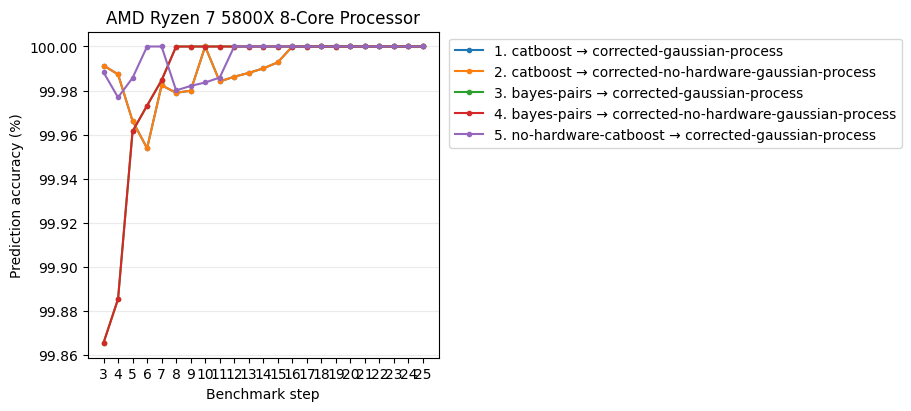

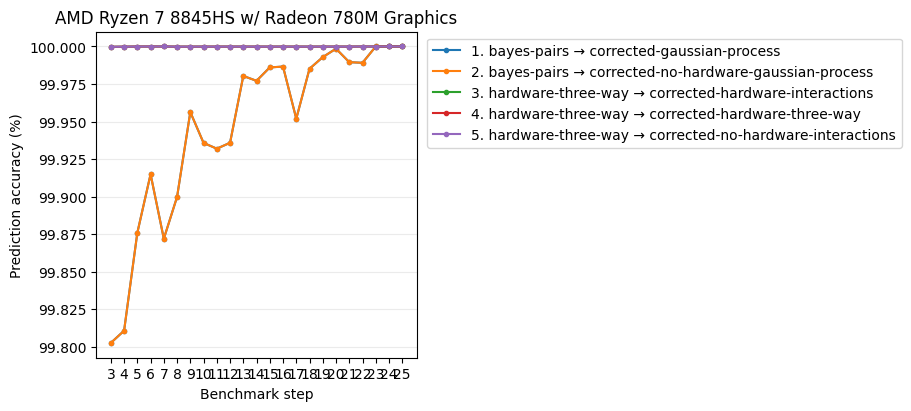

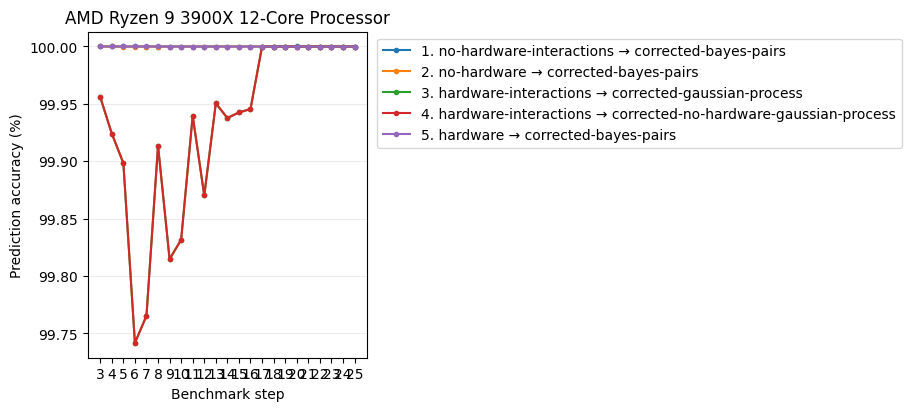

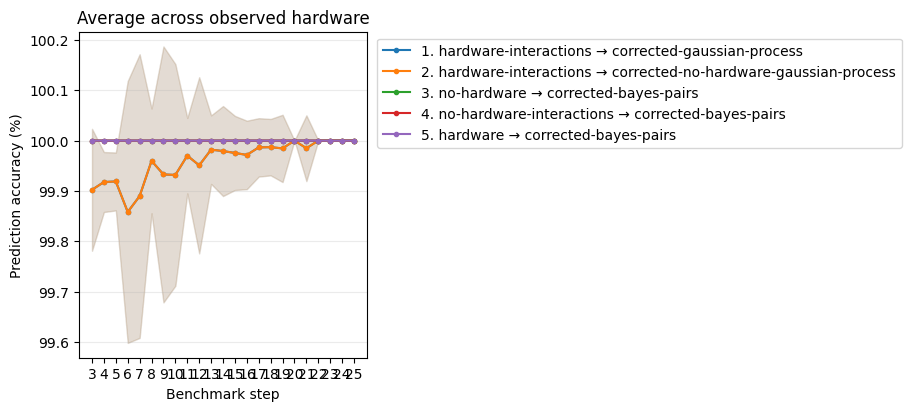

In [24]:
plot_progress(final_top)

## 2. First-to-last accuracy improvement

In [25]:
improvement_top = rankings("improvement", "pp", companions={
    "pool_share": "Final % of pool best", "pool_improvement": "Pool share gain (pp)",
})

#### AMD Ryzen 7 5800X 8-Core Processor

Eligible combinations: 420/420 ready · Range: -83.689251 to 2.5898291 pp
Tie-breaker: historical → local → application → workload (alphabetical); 2 tied at cutoff


,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Seeds,Final % of pool best,Pool share gain (pp)
1,llama.cpp,"[[0, 128], [512, 0]]",support-vector,corrected-no-hardware-small-mlp,2.58982908,—,—,1,98.932,1.91764
2,llama.cpp,"[[0, 128], [512, 0]]",support-vector,corrected-small-mlp,2.58982908,—,—,1,98.932,1.91764
3,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-no-hardware-small-mlp,2.14017023,—,—,1,99.5167,0
4,llama.cpp,"[[0, 128], [512, 0]]",small-mlp,corrected-small-mlp,2.14017023,—,—,1,99.5167,0
5,llama.cpp,"[[0, 128], [512, 0]]",kernel-ridge,corrected-no-hardware-small-mlp,1.80064508,—,—,1,98.932,0.62883


#### AMD Ryzen 7 8845HS w/ Radeon 780M Graphics

Eligible combinations: 420/420 ready · Range: -147.92058 to 71.596625 pp
Tie-breaker: historical → local → application → workload (alphabetical); 2 tied at cutoff


,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Seeds,Final % of pool best,Pool share gain (pp)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-random-forest,71.59662507,36.72149507,106.47175507,3,"96.8088 [83.078, 110.54]","70.6758 [56.945, 84.4065]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,random-forest,71.59662507,36.72149507,106.47175507,3,"96.8088 [83.078, 110.54]","70.6758 [56.945, 84.4065]"
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-catboost,corrected-no-hardware-random-forest,32.31701731,—,—,1,100,51.7955
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-catboost,corrected-random-forest,32.31701731,—,—,1,100,51.7955
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-no-hardware-random-forest,29.08369686,—,—,1,99.8217,51.6172


... (2 outputs left out)

,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Seeds,Final % of pool best,Pool share gain (pp)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-random-forest,595.57370252,396.81894399,794.32846106,3,"94.244 [89.911, 98.5771]","89.5692 [85.2361, 93.9023]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,random-forest,595.57370252,396.81894399,794.32846106,3,"94.244 [89.911, 98.5771]","89.5692 [85.2361, 93.9023]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,50.07182060,46.51327552,53.63036569,3,"96.5576 [96.3364, 96.7787]","12.0878 [-15.7122, 39.8877]"
4,llama.cpp,"[[0, 128], [512, 0]]",hardware-interactions,corrected-no-hardware-random-forest,9.70124890,—,—,1,88.6277,0
5,llama.cpp,"[[0, 128], [512, 0]]",hardware-interactions,corrected-random-forest,9.70124890,—,—,1,88.6277,0


#### Average across observed hardware

Eligible combinations: 109/109 ready · Range: -80.296305 to 222.39828 pp
Range of all eligible per-hardware means: -147.92058 to 595.5737 pp
Tie-breaker: historical → local → application → workload (alphabetical); no tie at cutoff


,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Platforms,Final % of pool best,Pool share gain (pp)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-random-forest,222.39828168,-585.33070866,1030.12727203,3,"96.8094 [90.436, 103.183]","54.2025 [-59.7644, 168.169]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,random-forest,222.39828168,-585.33070866,1030.12727203,3,"96.8094 [90.436, 103.183]","54.2025 [-59.7644, 168.169]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,23.92739985,-38.67660559,86.53140530,3,"96.6791 [91.4451, 101.913]","20.5004 [-39.1183, 80.1191]"
4,llama.cpp,"[[0, 128], [512, 0]]",hardware-interactions,corrected-no-hardware-random-forest,3.04609580,-25.23034791,31.32253952,3,"92.4738 [81.9504, 102.997]","0 [0, 0]"
5,llama.cpp,"[[0, 128], [512, 0]]",hardware-interactions,corrected-random-forest,3.04609580,-25.23034791,31.32253952,3,"92.4738 [81.9504, 102.997]","0 [0, 0]"


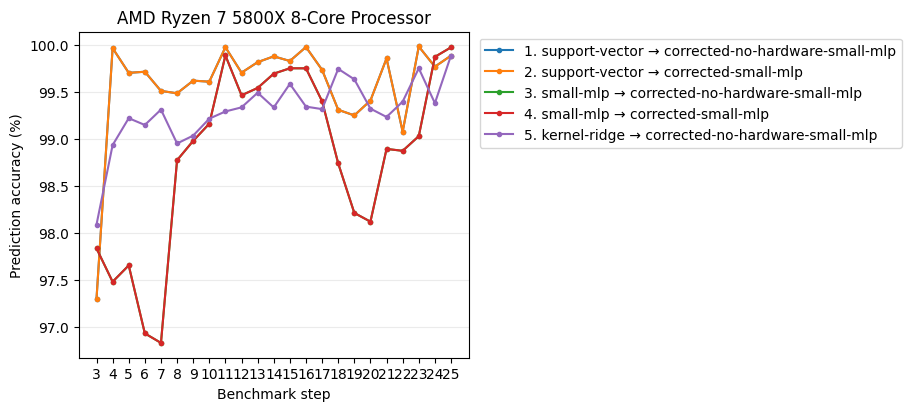

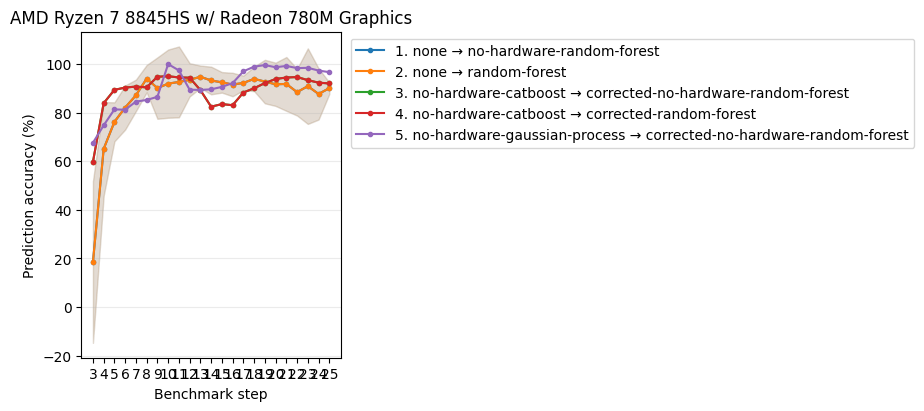

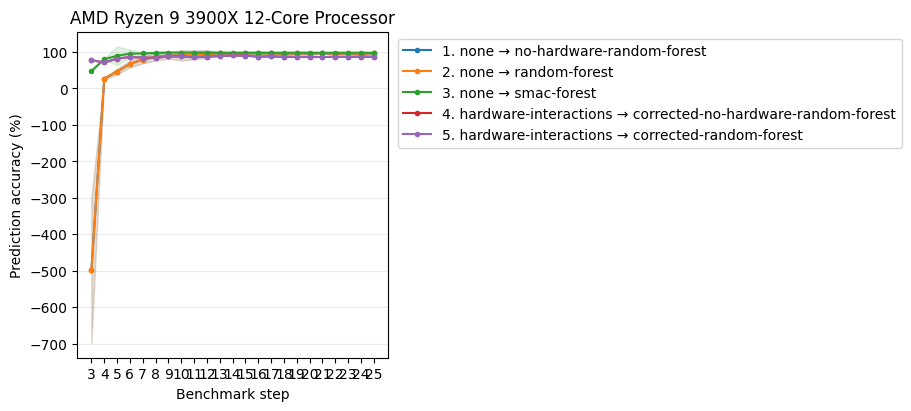

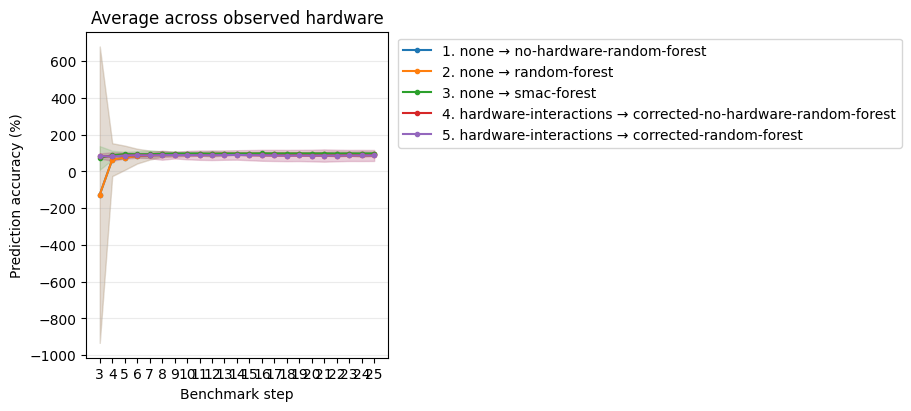

In [26]:
plot_progress(improvement_top)

## 3. Final recommendation quality

In [27]:
pool_final_top = rankings("pool_share", "%", companions={"accuracy": "Final prediction accuracy (%)"})

#### AMD Ryzen 7 5800X 8-Core Processor

Eligible combinations: 420/420 ready · Range: 95.922914 to 99.675133 %
Tie-breaker: historical → local → application → workload (alphabetical); 14 tied at cutoff


,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Seeds,Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-support-vector,99.67513339,98.97623001,100.37403678,3,"98.0216 [97.9438, 98.0995]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,support-vector,99.67513339,98.97623001,100.37403678,3,"98.0216 [97.9438, 98.0995]"
3,llama.cpp,"[[0, 128], [512, 0]]",gaussian-process,corrected-no-hardware-small-mlp,99.66083046,—,—,1,99.7613
4,llama.cpp,"[[0, 128], [512, 0]]",gaussian-process,corrected-small-mlp,99.66083046,—,—,1,99.7613
5,llama.cpp,"[[0, 128], [512, 0]]",gaussian-process,corrected-sparse-bayes,99.66083046,—,—,1,99.9642


#### AMD Ryzen 7 8845HS w/ Radeon 780M Graphics

Eligible combinations: 420/420 ready · Range: 69.352566 to 100 %
Tie-breaker: historical → local → application → workload (alphabetical); 248 tied at cutoff


,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Seeds,Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-sparse-bayes,100.00000000,—,—,1,98.088
2,llama.cpp,"[[0, 128], [512, 0]]",catboost,corrected-bayes-pairs,100.00000000,—,—,1,99.9999
3,llama.cpp,"[[0, 128], [512, 0]]",catboost,corrected-gaussian-process,100.00000000,—,—,1,99.9999
4,llama.cpp,"[[0, 128], [512, 0]]",catboost,corrected-hardware-interactions,100.00000000,—,—,1,99.998
5,llama.cpp,"[[0, 128], [512, 0]]",catboost,corrected-hardware-three-way,100.00000000,—,—,1,99.998


... (2 outputs left out)

,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Seeds,Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",hardware,corrected-bayes-pairs,100.00000000,—,—,1,99.9999
2,llama.cpp,"[[0, 128], [512, 0]]",hardware,corrected-gaussian-process,100.00000000,—,—,1,99.9026
3,llama.cpp,"[[0, 128], [512, 0]]",hardware,corrected-hardware,100.00000000,—,—,1,99.9987
4,llama.cpp,"[[0, 128], [512, 0]]",hardware,corrected-hardware-interactions,100.00000000,—,—,1,99.9943
5,llama.cpp,"[[0, 128], [512, 0]]",hardware,corrected-hardware-three-way,100.00000000,—,—,1,99.9943


#### Average across observed hardware

Eligible combinations: 109/109 ready · Range: 84.68459 to 99.643988 %
Range of all eligible per-hardware means: 69.352566 to 100 %
Tie-breaker: historical → local → application → workload (alphabetical); 11 tied at cutoff


,Application,Workload,Historical,Local,Mean (%),95% CI lower,95% CI upper,Platforms,Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",hardware-interactions,corrected-bayes-pairs,99.64398780,98.11219093,101.17578467,3,"99.9999 [99.9998, 100]"
2,llama.cpp,"[[0, 128], [512, 0]]",hardware-interactions,corrected-gaussian-process,99.64398780,98.11219093,101.17578467,3,"100 [99.9999, 100]"
3,llama.cpp,"[[0, 128], [512, 0]]",hardware-interactions,corrected-no-hardware-gaussian-process,99.64398780,98.11219093,101.17578467,3,"100 [99.9999, 100]"
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-gaussian-process,99.64398780,98.11219093,101.17578467,3,"99.949 [99.8382, 100.06]"
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-no-hardware-gaussian-process,99.64398780,98.11219093,101.17578467,3,"99.949 [99.8382, 100.06]"


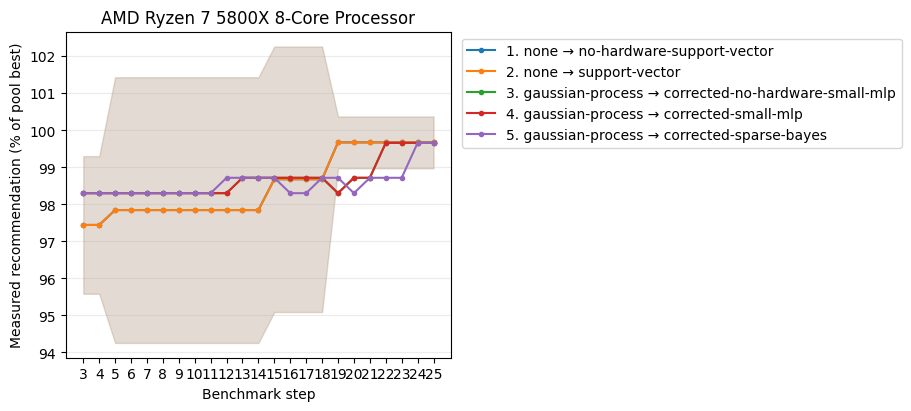

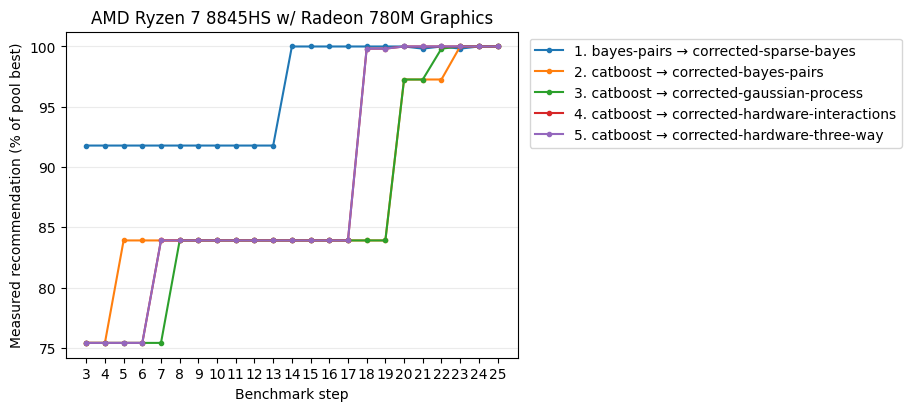

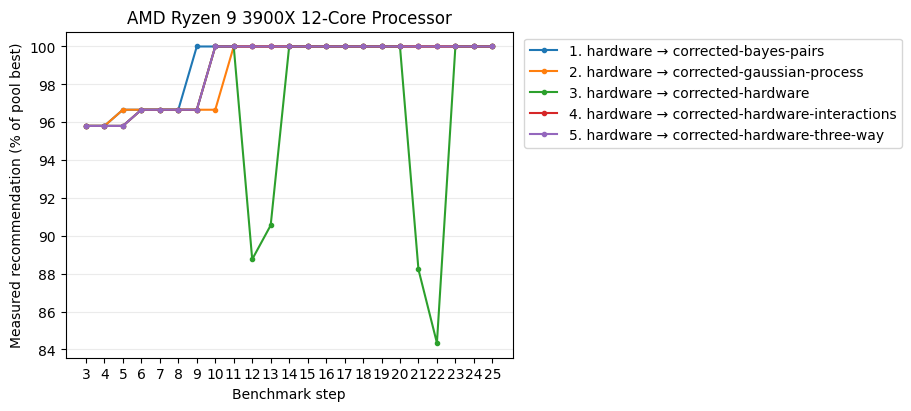

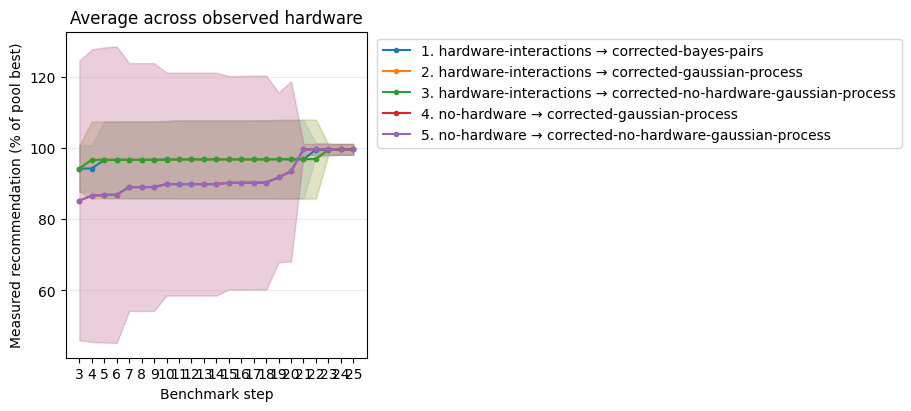

In [28]:
plot_progress(pool_final_top, "pool_share", "Measured recommendation (% of pool best)")

## 4. First-to-last recommendation quality improvement

In [29]:
pool_gain_top = rankings("pool_improvement", "pp", companions={
    "pool_share": "Final % of pool best", "accuracy": "Final prediction accuracy (%)",
    "improvement": "Prediction accuracy gain (pp)",
})

#### AMD Ryzen 7 5800X 8-Core Processor

Eligible combinations: 420/420 ready · Range: -1.5014935 to 3.0470124 pp
Tie-breaker: historical → local → application → workload (alphabetical); 6 tied at cutoff


,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Seeds,Final % of pool best,Final prediction accuracy (%),Prediction accuracy gain (pp)
1,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-gaussian-process,3.04701242,—,—,1,99.6608,99.8042,-0.0771086
2,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-hardware,3.04701242,—,—,1,99.6608,99.9277,-0.071047
3,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-no-hardware,3.04701242,—,—,1,99.6608,99.9277,-0.071047
4,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-no-hardware-gaussian-process,3.04701242,—,—,1,99.6608,99.8042,-0.0771086
5,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-no-hardware-small-mlp,3.04701242,—,—,1,99.6608,99.9317,0.683154


#### AMD Ryzen 7 8845HS w/ Radeon 780M Graphics

Eligible combinations: 420/420 ready · Range: -18.965456 to 70.675777 pp
Tie-breaker: historical → local → application → workload (alphabetical); 4 tied at cutoff


,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Seeds,Final % of pool best,Final prediction accuracy (%),Prediction accuracy gain (pp)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-random-forest,70.67577654,56.94504609,84.40650698,3,"96.8088 [83.078, 110.54]","90.0724 [87.6869, 92.4578]","71.5966 [36.7215, 106.472]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,random-forest,70.67577654,56.94504609,84.40650698,3,"96.8088 [83.078, 110.54]","90.0724 [87.6869, 92.4578]","71.5966 [36.7215, 106.472]"
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-catboost,corrected-no-hardware-random-forest,51.79550061,—,—,1,100,92.021,32.317
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-catboost,corrected-random-forest,51.79550061,—,—,1,100,92.021,32.317
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-kernel-ridge,corrected-no-hardware-random-forest,51.79550061,—,—,1,100,94.496,7.00531


... (2 outputs left out)

,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Seeds,Final % of pool best,Final prediction accuracy (%),Prediction accuracy gain (pp)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-random-forest,89.56923259,85.23613970,93.90232549,3,"94.244 [89.911, 98.5771]","96.7982 [95.8018, 97.7945]","595.574 [396.819, 794.328]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,random-forest,89.56923259,85.23613970,93.90232549,3,"94.244 [89.911, 98.5771]","96.7982 [95.8018, 97.7945]","595.574 [396.819, 794.328]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,12.08775420,-15.71222200,39.88773039,3,"96.5576 [96.3364, 96.7787]","97.9671 [97.2715, 98.6626]","50.0718 [46.5133, 53.6304]"
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-no-hardware-random-forest,11.91261517,—,—,1,100,96.2935,-2.02355
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-no-hardware-small-mlp,11.91261517,—,—,1,100,99.3942,1.01754


#### Average across observed hardware

Eligible combinations: 109/109 ready · Range: -5.7118375 to 54.202508 pp
Range of all eligible per-hardware means: -18.965456 to 89.569233 pp
Tie-breaker: historical → local → application → workload (alphabetical); no tie at cutoff


,Application,Workload,Historical,Local,Mean (pp),95% CI lower,95% CI upper,Platforms,Final % of pool best,Final prediction accuracy (%),Prediction accuracy gain (pp)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-random-forest,54.20250824,-59.76444805,168.16946453,3,"96.8094 [90.436, 103.183]","95.4873 [83.3324, 107.642]","222.398 [-585.331, 1030.13]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,random-forest,54.20250824,-59.76444805,168.16946453,3,"96.8094 [90.436, 103.183]","95.4873 [83.3324, 107.642]","222.398 [-585.331, 1030.13]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,20.50040154,-39.11831645,80.11911953,3,"96.6791 [91.4451, 101.913]","96.9261 [89.1291, 104.723]","23.9274 [-38.6766, 86.5314]"
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-no-hardware-random-forest,15.79896120,-29.06095440,60.65887679,3,"94.0699 [72.104, 116.036]","92.5827 [84.4638, 100.702]","-1.24779 [-13.0379, 10.5424]"
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-random-forest,15.79896120,-29.06095440,60.65887679,3,"94.0699 [72.104, 116.036]","92.5827 [84.4638, 100.702]","-1.24779 [-13.0379, 10.5424]"


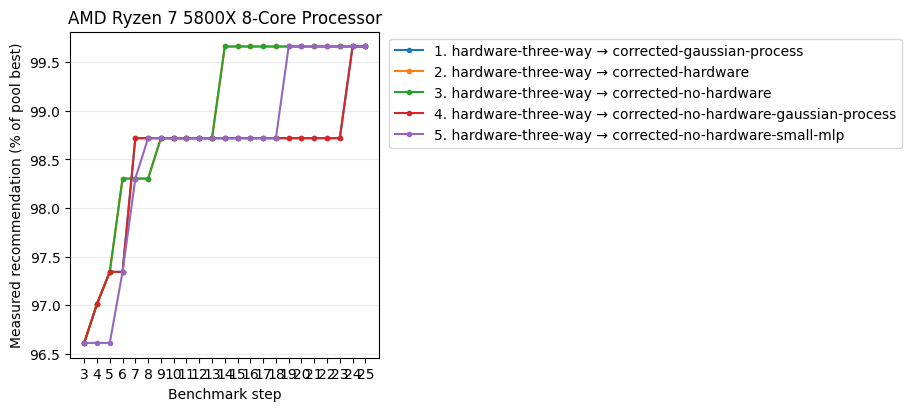

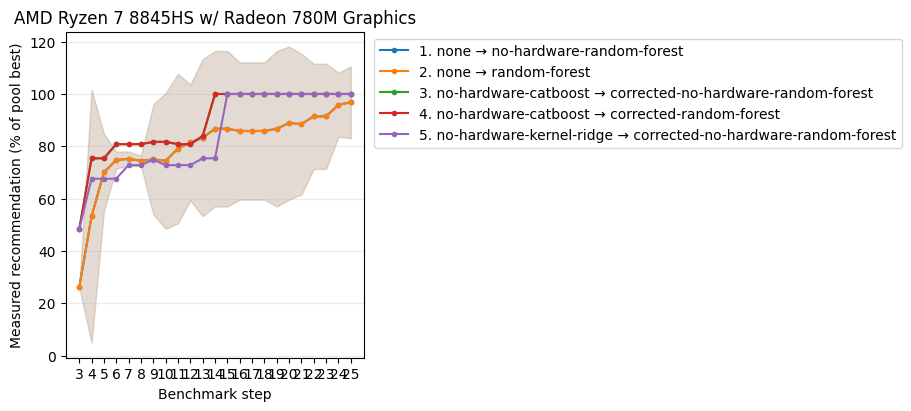

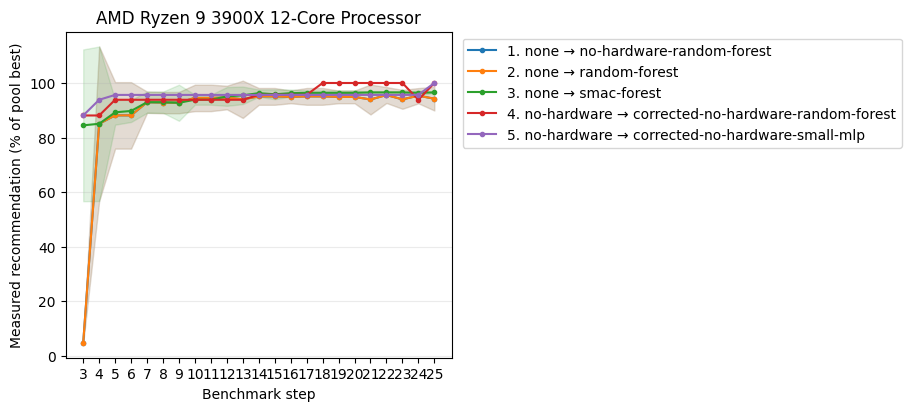

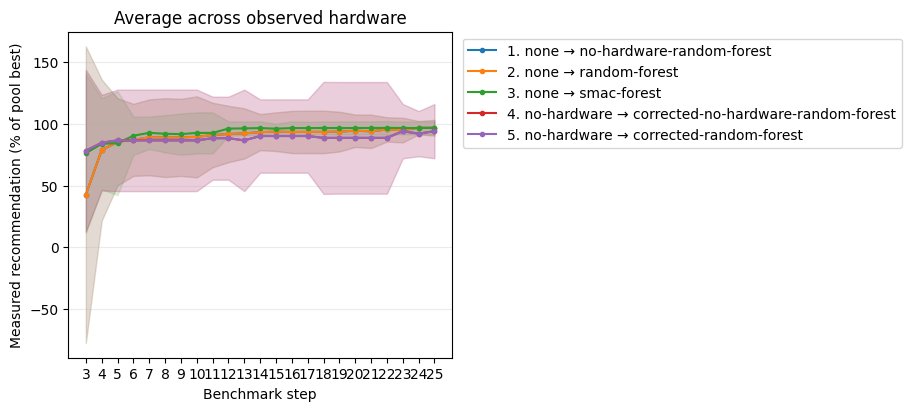

In [30]:
plot_progress(pool_gain_top, "pool_share", "Measured recommendation (% of pool best)")

## 5. Local convergence

- Round 1: first recommendation after startup, at benchmark step 3 in this evaluation
- Round 1 convergence: same recommended build throughout all reported rounds
- Final quality (%): measured throughput of the final recommendation ÷ best throughput sampled by that session × 100
- Above 100%: recommendation outside the sampled builds with higher measured throughput in the replay pool

In [31]:
convergence_top = rankings("convergence", "round", ascending=True)

#### AMD Ryzen 7 5800X 8-Core Processor

Final quality range: 96.84% to 100% of best sampled
Eligible combinations: 420/420 ready · Range: 1 to 23 round
Tie-breaker: historical → local → application → workload (alphabetical); 120 tied at cutoff


,Application,Workload,Historical,Local,Mean (round),95% CI lower,95% CI upper,Seeds,Final % of best sampled,Final % CI lower,Final % CI upper
1,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-catboost,1.00000000,—,—,1,98.31216310,—,—
2,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-kernel-ridge,1.00000000,—,—,1,98.31216310,—,—
3,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-no-hardware-catboost,1.00000000,—,—,1,98.31216310,—,—
4,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-no-hardware-kernel-ridge,1.00000000,—,—,1,98.31216310,—,—
5,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-no-hardware-random-forest,1.00000000,—,—,1,98.31216310,—,—


#### AMD Ryzen 7 8845HS w/ Radeon 780M Graphics

Final quality range: 69.48% to 100.2% of best sampled
Eligible combinations: 420/420 ready · Range: 1 to 23 round
Tie-breaker: historical → local → application → workload (alphabetical); 52 tied at cutoff


,Application,Workload,Historical,Local,Mean (round),95% CI lower,95% CI upper,Seeds,Final % of best sampled,Final % CI lower,Final % CI upper
1,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-bayes-pairs,1.00000000,—,—,1,100.00000000,—,—
2,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-gaussian-process,1.00000000,—,—,1,100.00000000,—,—
3,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-hardware,1.00000000,—,—,1,100.00000000,—,—
4,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-hardware-interactions,1.00000000,—,—,1,100.00000000,—,—
5,llama.cpp,"[[0, 128], [512, 0]]",bayes-pairs,corrected-hardware-three-way,1.00000000,—,—,1,100.00000000,—,—


... (2 outputs left out)

,Application,Workload,Historical,Local,Mean (round),95% CI lower,95% CI upper,Seeds,Final % of best sampled,Final % CI lower,Final % CI upper
1,llama.cpp,"[[0, 128], [512, 0]]",hardware-interactions,corrected-kernel-ridge,1.00000000,—,—,1,88.62765618,—,—
2,llama.cpp,"[[0, 128], [512, 0]]",hardware-interactions,corrected-no-hardware-kernel-ridge,1.00000000,—,—,1,88.62765618,—,—
3,llama.cpp,"[[0, 128], [512, 0]]",hardware-interactions,corrected-no-hardware-random-forest,1.00000000,—,—,1,88.62765618,—,—
4,llama.cpp,"[[0, 128], [512, 0]]",hardware-interactions,corrected-random-forest,1.00000000,—,—,1,88.62765618,—,—
5,llama.cpp,"[[0, 128], [512, 0]]",hardware-interactions,corrected-smac-forest,1.00000000,—,—,1,88.62765618,—,—


#### Average across observed hardware

Final quality range: 85.45% to 100% of best sampled
Eligible combinations: 109/109 ready · Range: 1 to 23 round
Range of all eligible per-hardware means: 1 to 23 round
Tie-breaker: historical → local → application → workload (alphabetical); 7 tied at cutoff


,Application,Workload,Historical,Local,Mean (round),95% CI lower,95% CI upper,Platforms,Final % of best sampled,Final % CI lower,Final % CI upper
1,llama.cpp,"[[0, 128], [512, 0]]",hardware-interactions,corrected-kernel-ridge,1.00000000,1.00000000,1.00000000,3,92.90641626,80.63568293,105.17714959
2,llama.cpp,"[[0, 128], [512, 0]]",hardware-interactions,corrected-no-hardware-kernel-ridge,1.00000000,1.00000000,1.00000000,3,92.90641626,80.63568293,105.17714959
3,llama.cpp,"[[0, 128], [512, 0]]",hardware-interactions,corrected-no-hardware-random-forest,1.00000000,1.00000000,1.00000000,3,92.90641626,80.63568293,105.17714959
4,llama.cpp,"[[0, 128], [512, 0]]",hardware-interactions,corrected-random-forest,1.00000000,1.00000000,1.00000000,3,92.90641626,80.63568293,105.17714959
5,llama.cpp,"[[0, 128], [512, 0]]",hardware-three-way,corrected-kernel-ridge,1.00000000,1.00000000,1.00000000,3,85.44530558,53.09943027,117.79118088


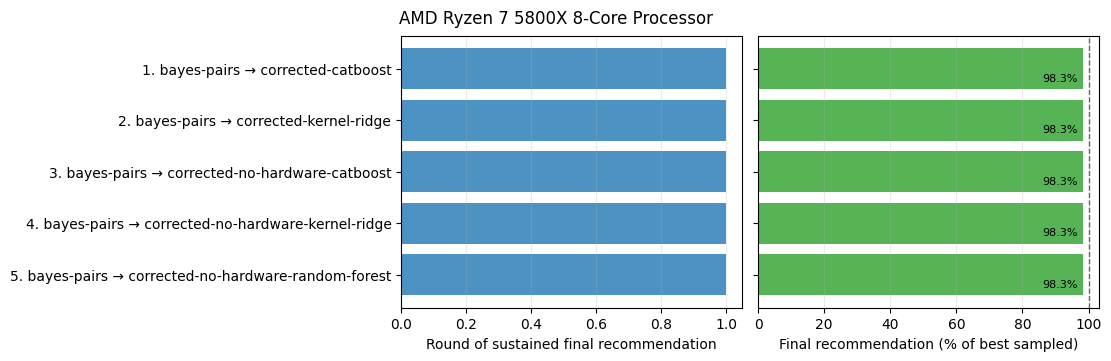

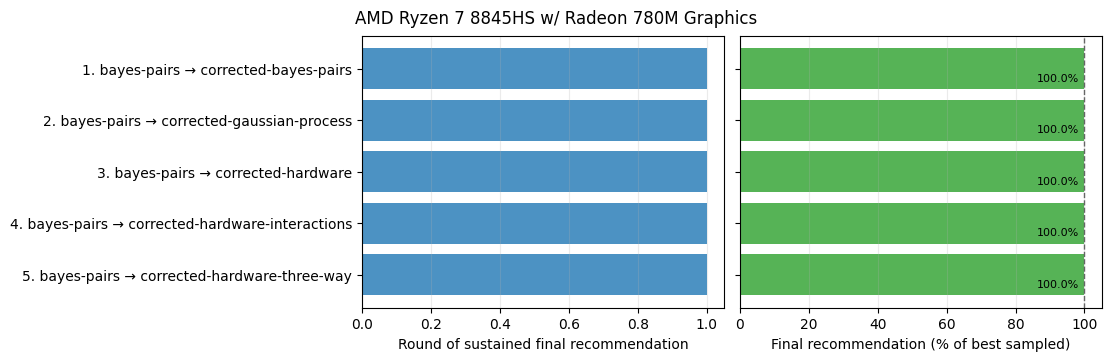

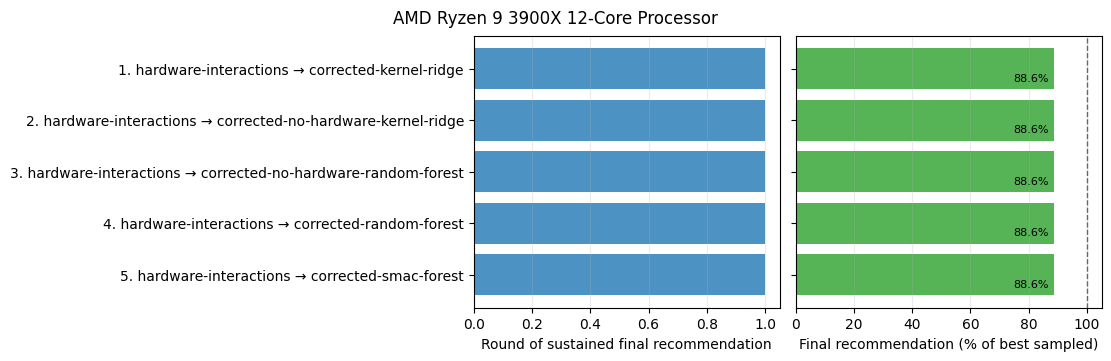

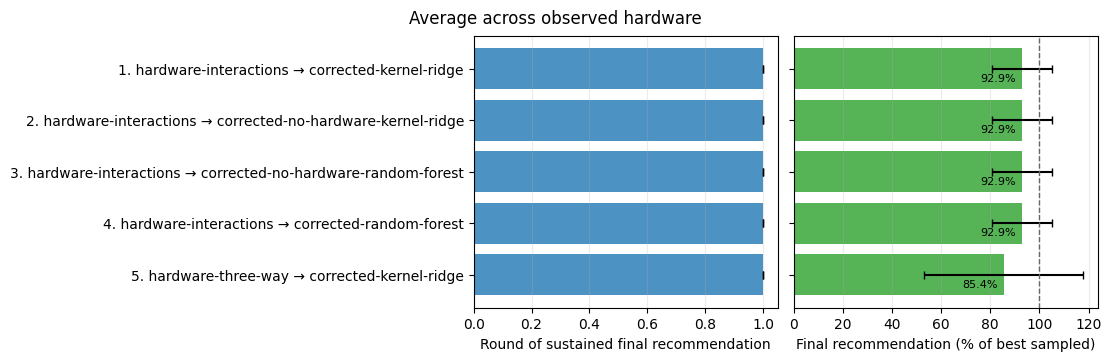

In [32]:
plot_bars(convergence_top, "Round of sustained final recommendation", show_final_quality=True)

## 6. Timing

- Ranking: mean time per round across the session
- Companion columns: final-round time and final prediction accuracy for the same combinations
- Companion values: mean [95% CI], where available

### Prediction

In [33]:
prediction_seconds_top = rankings("prediction_seconds", "ms", ascending=True, companions={
    "final_prediction_seconds": "Final-round time (ms)", "accuracy": "Final prediction accuracy (%)",
})

#### AMD Ryzen 7 5800X 8-Core Processor

Eligible combinations: 420/420 ready · Range: 84.411638 to 18210.805 ms
Tie-breaker: historical → local → application → workload (alphabetical); no tie at cutoff


,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Final-round time (ms),Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,84.41163783,54.84241888,113.98085677,3,"83.1106 [43.2007, 123.02]","99.9823 [99.9417, 100.023]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,108.25671068,95.88210165,120.63131970,3,"85.9877 [73.4367, 98.5387]","99.412 [99.3, 99.524]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,114.48161454,74.22649598,154.73673309,3,"78.6099 [33.9536, 123.266]","99.9823 [99.9417, 100.023]"
4,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,121.27329656,109.51017995,133.03641317,3,"122.629 [65.5599, 179.699]","99.6336 [99.1285, 100.139]"
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-no-hardware-gaussian-process,121.55871035,—,—,1,93.6745,99.9304


#### AMD Ryzen 7 8845HS w/ Radeon 780M Graphics

Eligible combinations: 420/420 ready · Range: 20.448088 to 9532.3569 ms
Tie-breaker: historical → local → application → workload (alphabetical); no tie at cutoff


,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Final-round time (ms),Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,20.44808783,15.16758019,25.72859546,3,"24.2269 [15.5537, 32.9001]","99.9596 [99.7859, 100.133]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,34.40844875,30.73946641,38.07743110,3,"41.7197 [30.2332, 53.2062]","81.9492 [28.2746, 135.624]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,36.95146887,18.93201073,54.97092701,3,"28.4769 [9.93939, 47.0143]","99.9596 [99.7859, 100.133]"
4,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,38.92271564,28.49713754,49.34829374,3,"44.2044 [26.446, 61.9627]","100 [99.9999, 100]"
5,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,51.06453262,34.14306328,67.98600197,3,"45.9471 [16.5191, 75.3752]","93.3991 [91.4966, 95.3017]"


... (2 outputs left out)

,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Final-round time (ms),Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,31.02902771,17.74683904,44.31121638,3,"24.5578 [12.8408, 36.2747]","99.8916 [99.6456, 100.138]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,35.09715052,25.19806586,44.99623519,3,"41.2126 [19.6243, 62.801]","99.8916 [99.6456, 100.138]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,40.47941626,19.93093135,61.02790117,3,"39.4354 [32.4263, 46.4444]","92.9314 [63.337, 122.526]"
4,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,46.98719058,20.39701847,73.57736268,3,"44.0345 [-9.26701, 97.3359]","76.5038 [1.82038, 151.187]"
5,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,54.30622616,34.54152275,74.07092957,3,"45.3849 [26.8351, 63.9347]","99.5417 [97.9694, 101.114]"


#### Average across observed hardware

Eligible combinations: 109/109 ready · Range: 45.296251 to 14735.294 ms
Range of all eligible per-hardware means: 20.448088 to 19006.822 ms
Tie-breaker: historical → local → application → workload (alphabetical); no tie at cutoff


,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Platforms,Final-round time (ms),Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,45.29625112,-39.87378534,130.46628758,3,"43.9651 [-40.2507, 128.181]","99.9445 [99.8273, 100.062]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,62.17674464,-50.37166969,174.72515898,3,"49.4331 [-15.2982, 114.164]","99.9445 [99.8273, 100.062]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,65.38705386,-55.07872592,185.85283364,3,"67.9281 [-49.7863, 185.643]","91.5047 [69.3261, 113.683]"
4,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,71.45040359,-51.56411178,194.46491896,3,"62.2579 [-15.786, 140.302]","92.1679 [58.4692, 125.867]"
5,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,73.15790156,-3.19013880,149.50594193,3,"59.3562 [2.06281, 116.65]","96.9261 [89.1291, 104.723]"


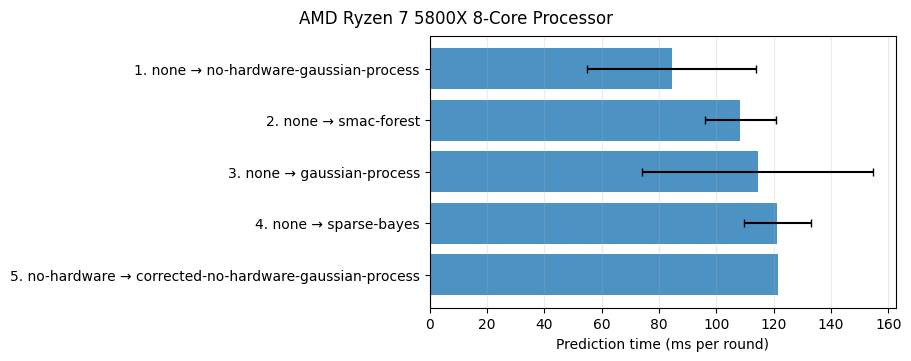

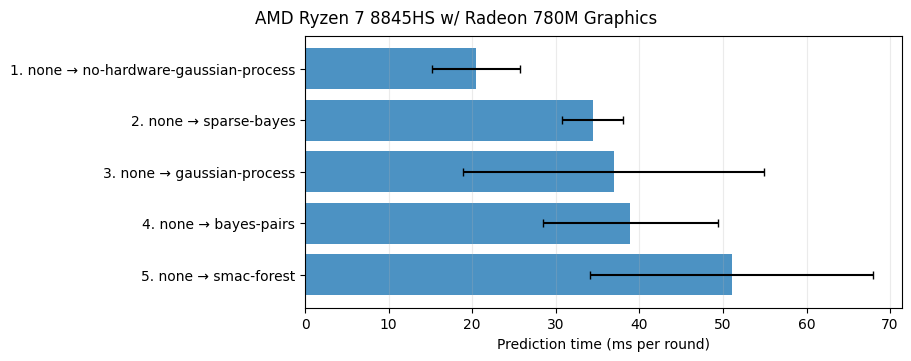

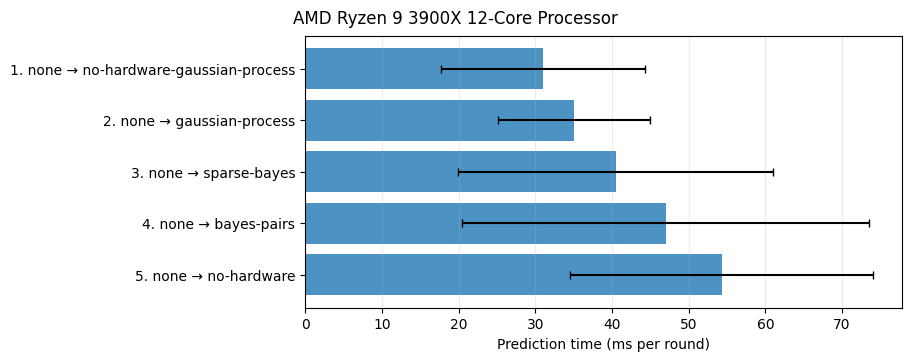

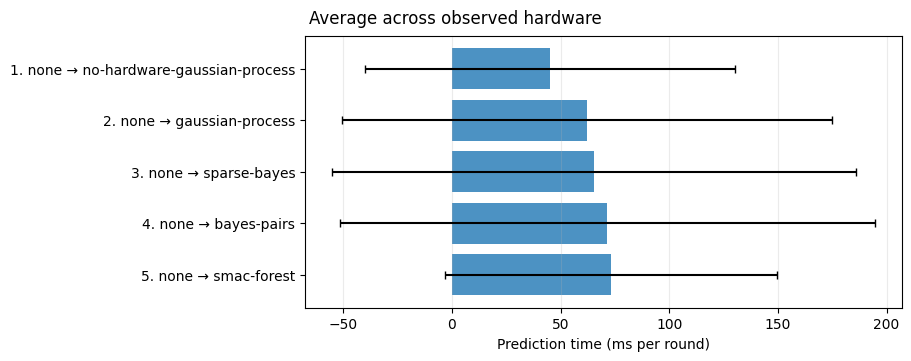

In [34]:
plot_bars(prediction_seconds_top, "Prediction time (ms per round)")

### Next sample

In [35]:
next_sample_seconds_top = rankings("next_sample_seconds", "ms", ascending=True, companions={
    "final_next_sample_seconds": "Final-round time (ms)", "accuracy": "Final prediction accuracy (%)",
})

#### AMD Ryzen 7 5800X 8-Core Processor

Eligible combinations: 420/420 ready · Range: 90.307692 to 18068.93 ms
Tie-breaker: historical → local → application → workload (alphabetical); no tie at cutoff


,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Final-round time (ms),Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,90.30769221,68.33390162,112.28148280,3,"90.6382 [16.0048, 165.272]","99.9823 [99.9417, 100.023]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,108.10323041,93.80112840,122.40533241,3,"83.062 [65.9722, 100.152]","99.412 [99.3, 99.524]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,110.73810271,100.80002802,120.67617739,3,"69.2068 [55.6475, 82.7661]","99.9823 [99.9417, 100.023]"
4,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,113.50774075,71.30462965,155.71085185,3,"100.426 [20.4743, 180.377]","100 [100, 100]"
5,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,116.56201587,88.05077381,145.07325793,3,"145.673 [-27.9318, 319.277]","99.6336 [99.1285, 100.139]"


#### AMD Ryzen 7 8845HS w/ Radeon 780M Graphics

Eligible combinations: 420/420 ready · Range: 21.891221 to 9671.5585 ms
Tie-breaker: historical → local → application → workload (alphabetical); no tie at cutoff


,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Final-round time (ms),Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,21.89122145,11.13641650,32.64602639,3,"22.946 [1.39975, 44.4923]","99.9596 [99.7859, 100.133]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,32.47108940,13.97539410,50.96678471,3,"30.4775 [7.9042, 53.0508]","99.9596 [99.7859, 100.133]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,33.92795039,28.82453842,39.03136236,3,"37.5847 [30.4483, 44.7211]","81.9492 [28.2746, 135.624]"
4,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,39.18752231,17.51578957,60.85925504,3,"42.4872 [7.26337, 77.711]","100 [99.9999, 100]"
5,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,50.57680143,46.07519514,55.07840772,3,"43.7833 [18.1945, 69.372]","93.3991 [91.4966, 95.3017]"


... (2 outputs left out)

,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Final-round time (ms),Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,28.82410481,16.37500771,41.27320191,3,"24.7798 [11.9672, 37.5923]","99.8916 [99.6456, 100.138]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,34.98885716,26.58173399,43.39598033,3,"31.0831 [-2.64339, 64.8097]","99.8916 [99.6456, 100.138]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,38.75945264,24.91723224,52.60167303,3,"38.8997 [12.3345, 65.4649]","92.9314 [63.337, 122.526]"
4,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,46.26524037,25.72805391,66.80242683,3,"61.2446 [-10.4811, 132.97]","76.5038 [1.82038, 151.187]"
5,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,53.29953497,41.62099675,64.97807318,3,"45.9123 [14.695, 77.1295]","99.5417 [97.9694, 101.114]"


#### Average across observed hardware

Eligible combinations: 109/109 ready · Range: 47.007673 to 14847.828 ms
Range of all eligible per-hardware means: 21.891221 to 19640.954 ms
Tie-breaker: historical → local → application → workload (alphabetical); no tie at cutoff


,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Platforms,Final-round time (ms),Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware-gaussian-process,47.00767282,-46.54196451,140.55731016,3,"46.1213 [-49.6761, 141.919]","99.9445 [99.8273, 100.062]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,gaussian-process,59.39934976,-51.09132735,169.89002686,3,"43.5891 [-11.5279, 98.7062]","99.9445 [99.8273, 100.062]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,63.08313963,-52.12377869,178.29005796,3,"74.0524 [-80.035, 228.14]","91.5047 [69.3261, 113.683]"
4,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,66.32016781,-35.57563056,168.21596618,3,"68.0524 [-5.38623, 141.491]","92.1679 [58.4692, 125.867]"
5,llama.cpp,"[[0, 128], [512, 0]]",none,smac-forest,73.56080436,-2.09415376,149.21576248,3,"57.1295 [1.33225, 112.927]","96.9261 [89.1291, 104.723]"


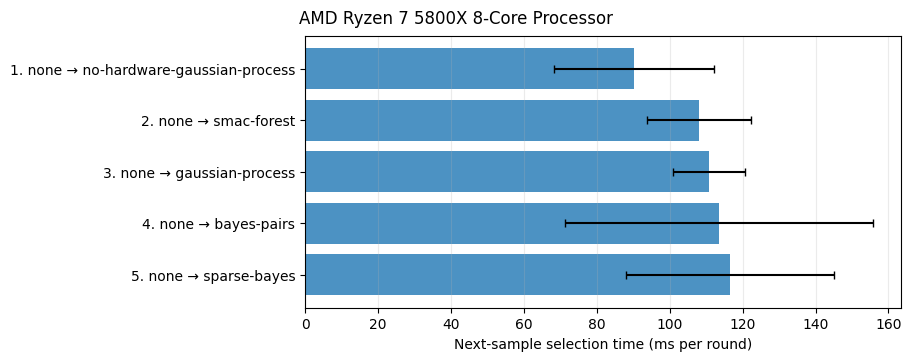

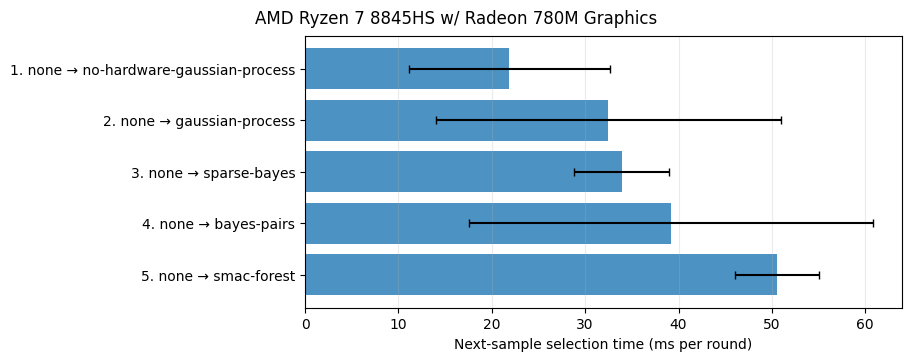

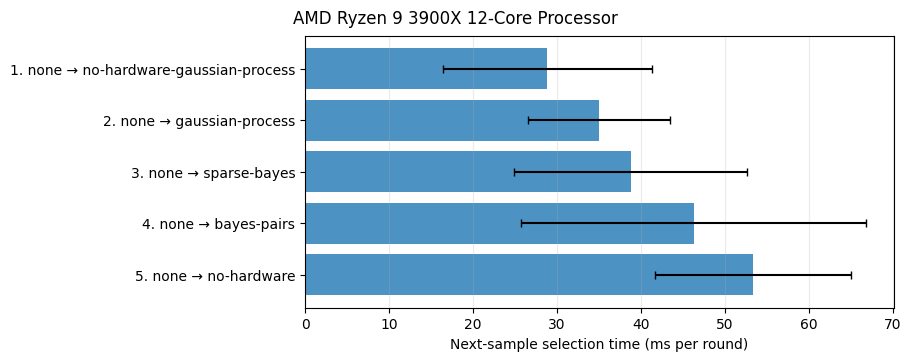

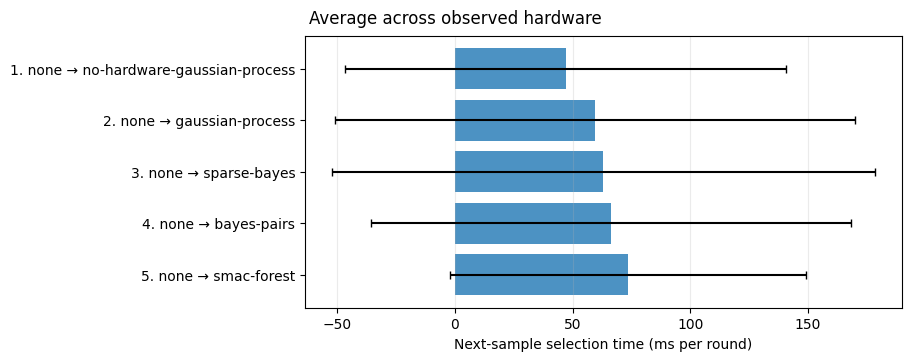

In [36]:
plot_bars(next_sample_seconds_top, "Next-sample selection time (ms per round)")

### Refitting

In [37]:
refit_seconds_top = rankings("refit_seconds", "ms", ascending=True, companions={
    "final_refit_seconds": "Final-round time (ms)", "accuracy": "Final prediction accuracy (%)",
})

#### AMD Ryzen 7 5800X 8-Core Processor

Eligible combinations: 420/420 ready · Range: 82.946742 to 15897.372 ms
Tie-breaker: historical → local → application → workload (alphabetical); no tie at cutoff


,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Final-round time (ms),Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-no-hardware,82.94674173,—,—,1,107.366,99.9988
2,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-no-hardware,97.77428031,—,—,1,109.717,99.9938
3,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-hardware,115.90355260,—,—,1,115.073,99.9988
4,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,119.15368783,76.71599324,161.59138242,3,"92.9772 [55.9681, 129.986]","100 [100, 100]"
5,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-bayes-pairs,129.41145262,—,—,1,177.669,100


#### AMD Ryzen 7 8845HS w/ Radeon 780M Graphics

Eligible combinations: 420/420 ready · Range: 101.0279 to 11779.756 ms
Tie-breaker: historical → local → application → workload (alphabetical); no tie at cutoff


,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Final-round time (ms),Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-no-hardware,101.02789826,—,—,1,130.77,99.9999
2,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,101.49396003,64.53950514,138.44841492,3,"130.168 [-0.68232, 261.019]","97.0124 [90.2294, 103.795]"
3,llama.cpp,"[[0, 128], [512, 0]]",gaussian-process,corrected-no-hardware,120.36736835,—,—,1,132.56,99.1652
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware-gaussian-process,corrected-hardware,124.64898079,—,—,1,171.874,99.9999
5,llama.cpp,"[[0, 128], [512, 0]]",sparse-bayes,corrected-no-hardware,135.57729561,—,—,1,190.814,89.8339


... (2 outputs left out)

,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Seeds,Final-round time (ms),Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,64.90841381,36.55195489,93.26487273,3,"57.5494 [9.14482, 105.954]","99.5417 [97.9694, 101.114]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,119.51571710,57.61785776,181.41357644,3,"167.754 [-146.088, 481.597]","76.5038 [1.82038, 151.187]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,126.83124389,64.69103595,188.97145182,3,"138.348 [54.4934, 222.202]","92.9314 [63.337, 122.526]"
4,llama.cpp,"[[0, 128], [512, 0]]",none,hardware,129.18665430,69.60575119,188.76755741,3,"146.749 [139.828, 153.671]","99.5417 [97.9694, 101.114]"
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-no-hardware,172.57060625,—,—,1,240.133,97.8404


#### Average across observed hardware

Eligible combinations: 109/109 ready · Range: 115.74374 to 15095.237 ms
Range of all eligible per-hardware means: 64.908414 to 20184.691 ms
Tie-breaker: historical → local → application → workload (alphabetical); no tie at cutoff


,Application,Workload,Historical,Local,Mean (ms),95% CI lower,95% CI upper,Platforms,Final-round time (ms),Final prediction accuracy (%)
1,llama.cpp,"[[0, 128], [512, 0]]",none,no-hardware,115.74374434,-31.46483285,262.95232153,3,"165.66 [-156.172, 487.491]","98.4803 [95.2193, 101.741]"
2,llama.cpp,"[[0, 128], [512, 0]]",none,bayes-pairs,128.33171915,89.61806918,167.04536913,3,"137.55 [39.663, 235.436]","92.1679 [58.4692, 125.867]"
3,llama.cpp,"[[0, 128], [512, 0]]",none,sparse-bayes,144.56722067,104.86404524,184.27039611,3,"176.162 [43.272, 309.053]","91.5047 [69.3261, 113.683]"
4,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-no-hardware,158.97252178,127.57121864,190.37382492,3,"159.293 [-17.4133, 335.999]","99.2729 [96.191, 102.355]"
5,llama.cpp,"[[0, 128], [512, 0]]",no-hardware,corrected-bayes-pairs,173.89168546,126.92157157,220.86179936,3,"159.567 [127.773, 191.361]","100 [99.9999, 100]"


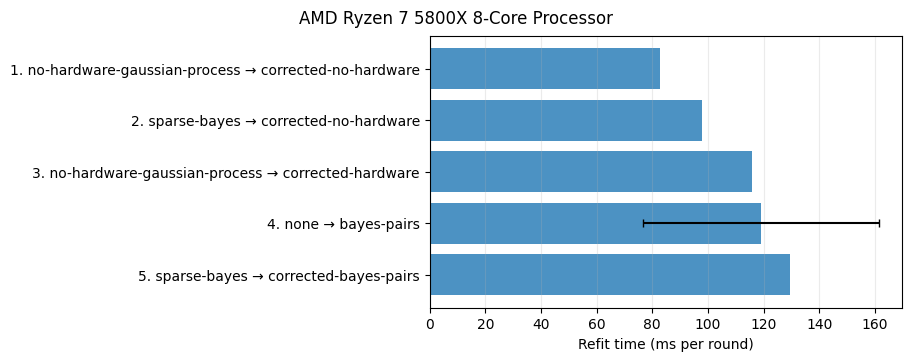

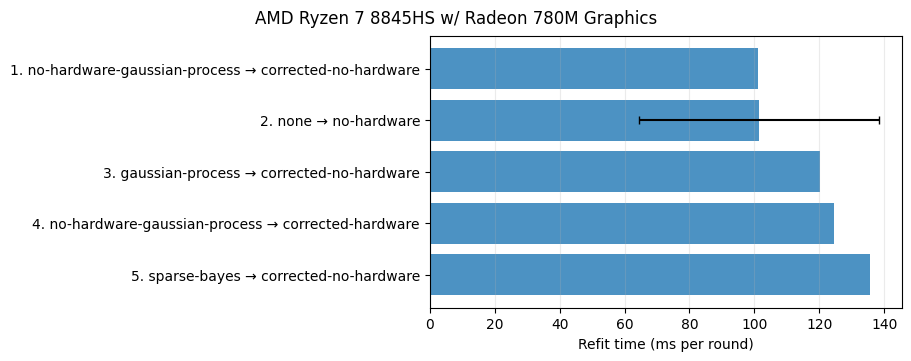

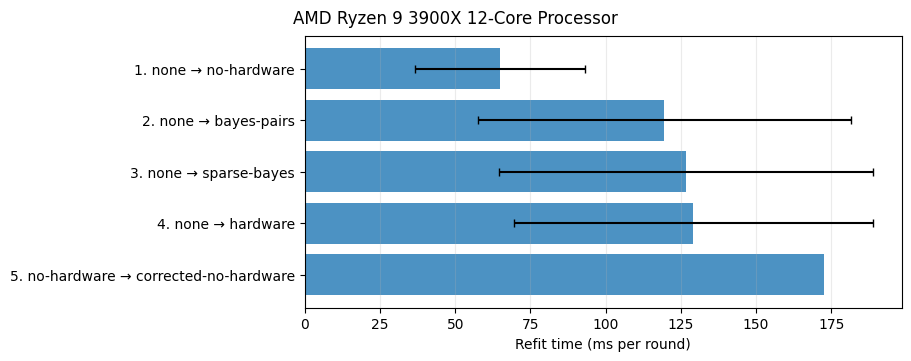

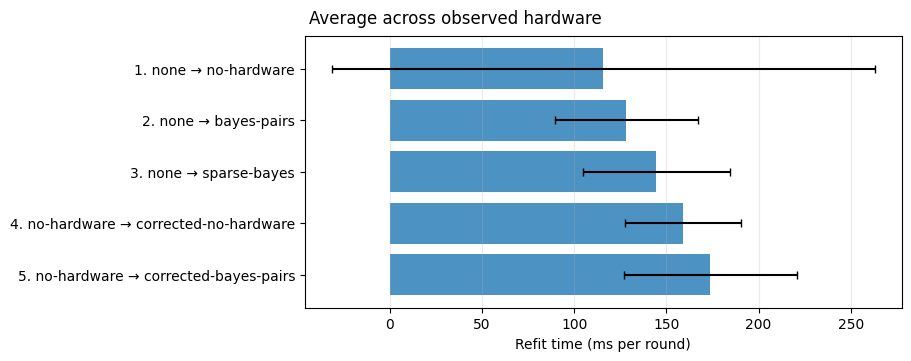

In [38]:
plot_bars(refit_seconds_top, "Refit time (ms per round)")